# Adult Income: EDA

We are looking at which features are related to earning over $50K and checking the male and female groups before the fairness audit.

This notebook describes all 48,842 records. For modeling, we still need separate training, validation, and audit data. Feature choices and model tuning should use the training/validation data, with audit data kept separate.



My part focuses on exploring the Adult dataset to see which features might help predict whether someone earns over $50K

## Load the data
Run the notebook from the top in Colab. The dataset is fetched from UCI, so this step needs internet access.

In [ ]:
%pip install -q ucimlrepo

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from ucimlrepo import fetch_ucirepo

adult = fetch_ucirepo(id=2)
X = adult.data.features
y = adult.data.targets

new_df = X.join(y).copy()
print("Rows and columns:", new_df.shape)
display(new_df.head())

## Prepare the income labels
Some income labels end with a period. We remove that so both versions map correctly. `False` means $50K or less; `True` means over $50K. We read from the original target column so rerunning this cell does not remap existing booleans.

In [ ]:
income_labels = y["income"].astype("string").str.strip().str.rstrip(".")
assert income_labels.isin(["<=50K", ">50K"]).all(), "Check unexpected income labels."
new_df["income"] = income_labels.map({"<=50K": False, ">50K": True}).astype("boolean")

new_df["income"].value_counts(dropna=False)

,count
income,
False,37155
True,11687


In [ ]:
new_df["income"].value_counts(normalize=True).mul(100).round(2)

- There are 37,155 records earning $50K or less and 11,687 earning over $50K.
- That is about 76.07% versus 23.93%, so the income categories are uneven. A model that always chooses the larger category could get about 76% accuracy while missing every high-income person.

## Missing values
We checked both question marks and recognized nulls because pandas initially treats `"?"` as text.

In [ ]:
new_df[["workclass", "occupation", "native-country"]].apply(
    lambda col: col.astype("string").str.strip().eq("?").sum()
)

,0
workclass,1836
occupation,1843
native-country,583


In [ ]:
new_df = new_df.replace("?", pd.NA)

new_df.isna().sum()

,0
age,0
workclass,2799
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,2809
relationship,0
race,0
sex,0


- Workclass has 2,799 missing values, occupation has 2,809, and native country has 857 after combining both formats.
- These are missing cells, not separate people. One record can be missing more than one field.
- We only standardized the missing-value format here. My partner is handling how to fill or remove missing values.

In [ ]:
new_df[["workclass", "occupation", "native-country"]].isna().groupby(
    new_df["sex"]
).mean().mul(100).round(2)

,workclass,occupation,native-country
sex,,,
Female,7.84,7.86,1.53
Male,4.68,4.70,1.87


- About 7.84% of female records are missing workclass, compared with 4.68% of male records. Occupation follows a similar pattern: 7.86% versus 4.70%.
- Dropping rows with missing work information would remove a larger percentage of female records. We should check group sizes again after cleaning.
- Native country is missing slightly more often for males: 1.87% versus 1.53%.

## Compare categories
The function shows counts and percentages within each row. For income comparisons, the `True` percentage is the share earning over $50K within that category. Missing entries in either selected column are excluded from that comparison.

In [ ]:
def compare_categories(data, feat1, feat2):
    # Number of records in each combination
    counts = pd.crosstab(data[feat1], data[feat2])

    # Percentages within each category of feature1
    percentages = pd.crosstab(
        data[feat1],
        data[feat2],
        normalize="index"
    ).mul(100).round(2)

    print("Counts:")
    display(counts)

    print("Row percentages:")
    display(percentages)

### Education

In [ ]:
compare_categories(new_df, "education", "income")

Counts:


income,False,True
education,,
10th,1302,87
11th,1720,92
12th,609,48
1st-4th,239,8
5th-6th,482,27
7th-8th,893,62
9th,715,41
Assoc-acdm,1188,413
Assoc-voc,1539,522


Row percentages:


income,False,True
education,,
10th,93.74,6.26
11th,94.92,5.08
12th,92.69,7.31
1st-4th,96.76,3.24
5th-6th,94.70,5.30
7th-8th,93.51,6.49
9th,94.58,5.42
Assoc-acdm,74.20,25.80
Assoc-voc,74.67,25.33


- Higher education levels generally have higher percentages earning over $50K.
- About 15.86% of high school graduates earn over $50K, compared with 41.28% of bachelor’s graduates, 54.91% of master’s graduates, and 72.56% of doctorate holders.
- Education looks useful for predicting income. This shows an association; it does not tell us that education alone causes higher income.

### Occupation

In [ ]:
compare_categories(new_df, "occupation", "income")

Counts:


income,False,True
occupation,,
Adm-clerical,4843,768
Armed-Forces,10,5
Craft-repair,4729,1383
Exec-managerial,3178,2908
Farming-fishing,1317,173
Handlers-cleaners,1934,138
Machine-op-inspct,2650,372
Other-service,4719,204
Priv-house-serv,239,3


Row percentages:


income,False,True
occupation,,
Adm-clerical,86.31,13.69
Armed-Forces,66.67,33.33
Craft-repair,77.37,22.63
Exec-managerial,52.22,47.78
Farming-fishing,88.39,11.61
Handlers-cleaners,93.34,6.66
Machine-op-inspct,87.69,12.31
Other-service,95.86,4.14
Priv-house-serv,98.76,1.24


- Income rates differ a lot across occupations. About 47.78% of executive/managerial workers and 45.11% of professional-specialty workers earn over $50K, compared with 4.14% in other service jobs.
- Those categories each have thousands of records, so the differences are not based on just a few people.
- Armed-Forces has only 15 records. Its 33.33% rate is based on 5 people, so we should be careful about generalizing from it.
- Occupation looks like another useful candidate predictor. This table leaves out the 2,809 records with missing occupation.

### Workclass

In [ ]:
compare_categories(new_df, "workclass", "income")

Counts:


income,False,True
workclass,,
Federal-gov,871,561
Local-gov,2209,927
Never-worked,10,0
Private,26519,7387
Self-emp-inc,757,938
Self-emp-not-inc,2785,1077
State-gov,1451,530
Without-pay,19,2


Row percentages:


income,False,True
workclass,,
Federal-gov,60.82,39.18
Local-gov,70.44,29.56
Never-worked,100.00,0.00
Private,78.21,21.79
Self-emp-inc,44.66,55.34
Self-emp-not-inc,72.11,27.89
State-gov,73.25,26.75
Without-pay,90.48,9.52


- Workclass describes the type of employment, while occupation describes the kind of job.
- About 55.34% of incorporated self-employed workers earn over $50K, compared with 39.18% of federal government workers and 21.79% of private-sector workers.
- Workclass may help predict income, but we need modeling to check whether it adds information beyond the other features.
- Never-worked has only 10 records and Without-pay has 21, so their percentages are based on small samples.
- This comparison includes 46,043 records and leaves out the 2,799 with missing workclass.

## Age and weekly work hours

In [ ]:
new_df.groupby("income")[
    ["age", "hours-per-week"]
].agg(["mean", "median"]).round(2)

age        hours-per-week       
         mean median           mean median
income                                    
False   36.87   34.0          38.84   40.0
True    44.28   43.0          45.45   40.0

- People earning over $50K are about 7.4 years older on average: 44.28 versus 36.87. Their median ages are also different: 43 versus 34.
- The higher-income group works about 6.6 more hours per week on average: 45.45 versus 38.84.
- Both groups have a median of 40 work hours, so the averages alone do not show the whole pattern.

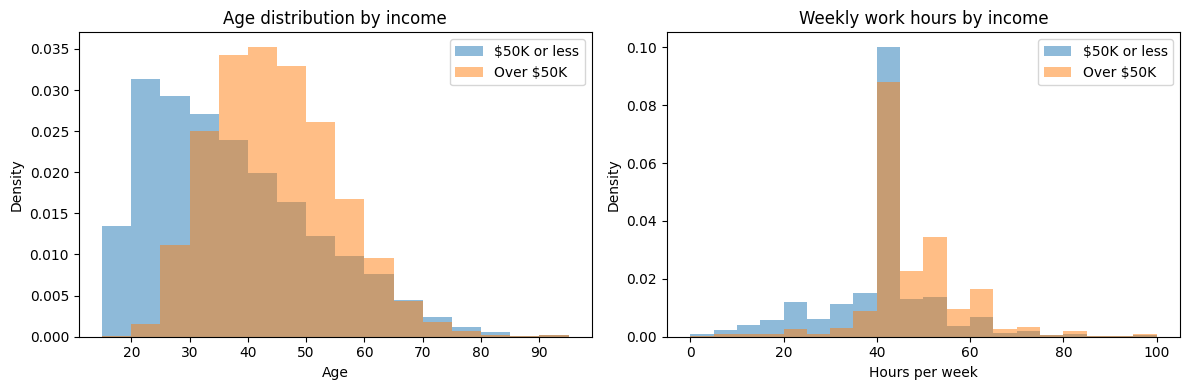

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for income, label in [(False, "$50K or less"), (True, "Over $50K")]:
    group = new_df[new_df["income"] == income]

    axes[0].hist(
        group["age"], bins=range(15, 96, 5),
        density=True, alpha=0.5, label=label
    )

    axes[1].hist(
        group["hours-per-week"], bins=range(0, 101, 5),
        density=True, alpha=0.5, label=label
    )

axes[0].set_title("Age distribution by income")
axes[0].set_xlabel("Age")

axes[1].set_title("Weekly work hours by income")
axes[1].set_xlabel("Hours per week")

for ax in axes:
    ax.set_ylabel("Density")
    ax.legend()

plt.tight_layout()
plt.show()



- The higher-income age distribution is shifted toward older ages, with much of it around ages 35–55. The lower-income group has a larger share in their 20s.
- Both groups have their tallest work-hours bar around 40 hours. The higher-income group has a larger share around 45–65 hours, while the lower-income group has a larger share under 40.
- These are density plots, so we are comparing the shapes within each income group rather than raw numbers of people. Each group’s total histogram area is 1.
- There is still a lot of overlap. Age and work hours may help, but neither one separates the income categories on its own.

## Male and female groups

In [ ]:
new_df['sex'].value_counts()

,count
sex,
Male,32650
Female,16192


In [ ]:
compare_categories(new_df, "sex", "income")

Counts:


income,False,True
sex,,
Female,14423,1769
Male,22732,9918


Row percentages:


income,False,True
sex,,
Female,89.07,10.93
Male,69.62,30.38


- There are 32,650 male records and 16,192 female records, so there are about twice as many male records.
- About 30.38% of males earn over $50K, compared with 10.93% of females. That is a gap of about 19.45 percentage points.
- There are 9,918 high-income male records and 1,769 high-income female records. We will have fewer high-income female examples after splitting the data, which could make performance estimates for that group less precise.
- These are actual income differences in the data. Once we have predictions, we can compare how well the model identifies high-income people within each group.

In [ ]:
new_df.groupby("sex")[
    ["age", "education-num", "hours-per-week"]
].agg(["mean", "median"])

age        education-num        hours-per-week       
             mean median          mean median           mean median
sex                                                                
Female  36.927989   35.0     10.044034   10.0      36.400692   40.0
Male    39.494395   38.0     10.094977   10.0      42.416845   40.0

- Male records have a higher average age (39.49 versus 36.93) and more weekly work hours on average (42.42 versus 36.40).
- The average education-num values are close: 10.09 for males and 10.04 for females. Both medians are 10. This does not mean the full education distributions are identical.
- These differences give us background for the fairness audit, but they do not establish why the income gap exists.

## Features that look promising so far

Based on this EDA, we think **education, occupation, workclass, age, and hours-per-week** are reasonable candidate predictors of whether someone earns over $50K.

- **Education:** income rates generally rise with higher education levels. Education and education-num describe the same underlying education level, so we should check their overlap before deciding how to represent it in the model.
- **Occupation:** there are clear differences in income rates across job categories.
- **Workclass:** income rates also differ across employment types.
- **Age:** the higher-income group tends to be older.
- **Hours-per-week:** the higher-income group works more hours on average, although both groups overlap a lot.

These are promising features, not a final ranking. We have not yet checked every other feature, so we should not drop the remaining ones just because they are not listed here. Model validation will tell us how much each feature helps when used together.

We need to keep **sex** available for comparing the male and female groups in the audit. Whether to also use it as a model input should follow the paper’s setup and our team’s plan.

Next, we will rerun these comparisons on the finalized dataframe and check the group counts after cleaning.